# Geographic experiments: population features, regional holdout, and water access

This notebook contains experiments surrounding additional geographic population and region data from the [WorldPop](https://hub.worldpop.org/geodata/listing?id=136) and [GeoBoundaries](https://www.geoboundaries.org/) datasets. We create nearby population features derived from each well's coordinates and implement regional hold-out sets to accomodate our dashboard's data visualizations.

## 1. Setup and experiment parameters

\<write here on data dependencies, cached features, the holdout region, repair budget, and distinct catchment and access thresholds>

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio
from IPython.display import display
from water_wells import DataConfig, DataLoader, TrainingConfig, TrainingPipeline, ModelEvaluator, POPULATION_COLUMNS
from water_wells.kpi_metrics import (
    assign_population_regions, build_population_access_df, calculate_access_kpis,
    select_interventions, select_access_interventions,
)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
raster_path = ROOT / "tza_pop_2026_CN_1km_R2025A_UA_v1.tif"
boundaries_path = ROOT / "data/raw/geoBoundaries-TZA-ADM1.geojson"
holdout_regions = ["Morogoro"]
nearby_radius_m = 2_500
access_distance_m = 2_500
budget_n = 300
random_state = 42

## 2. Population raster to a coordinate dataframe



In [2]:
with rasterio.open(raster_path) as raster:
    population_crs = raster.crs.to_string()
    population_band = raster.read(1, masked=True)
    rows, cols = np.where(~np.ma.getmaskarray(population_band) & np.isfinite(population_band.data))
    x, y = rasterio.transform.xy(raster.transform, rows, cols, offset="center")
    population_df = pd.DataFrame({
        "pixel_id": rows.astype(np.int64) * raster.width + cols,
        "x": x, "y": y, "population": population_band.data[rows, cols].astype(float),
    })
del population_band
population_df.head()

,pixel_id,x,y,population
0,170,30.762499,-0.987500,142.387009
1,171,30.770832,-0.987500,18.808517
2,1502,30.754166,-0.995833,40.088570
3,1503,30.762499,-0.995833,95.127190
4,1504,30.770832,-0.995833,25.027851


## 3. Population-radius features and readable exploration

Since our initial population fields were deemed unreliable, we extract population radius sums for 1, 2, 3, 5, 10 and 20 kilometers and include them as features in our data.

In [3]:
X_raw, y = DataLoader(DataConfig(data_dir=ROOT)).load_training()
config = TrainingConfig()
pipeline = TrainingPipeline(
    config, population_raster=raster_path,
    cache_dir=ROOT / "data/processed/population", data_mode="auto",
)
X_model = pipeline.prepare_population_data(X_raw)
population_features = list(POPULATION_COLUMNS.values())
from water_wells import FeatureEngineer
exploration_features = FeatureEngineer().fit_transform(X_model)
training_df = exploration_features.assign(id=X_raw["id"], status_group=y)
display(training_df[["id", "population", *population_features]].head())
display(training_df[population_features].describe())

,id,population,Population_1km,Population_2km,Population_3km,population_5km,population_10km,population_20km
0,69572,109,956.509750,1542.205973,1955.479350,2588.417220,6063.172768,20983.922468
1,8776,280,563.686104,1692.846846,2704.024260,3565.205803,4922.414818,6793.852446
2,34310,250,5265.049713,5817.321788,7392.557673,9522.889765,16132.292455,49572.231660
3,67743,58,943.303563,2292.345521,3668.818283,8637.310509,16060.100572,39220.543976
4,19728,0,1635.062378,3825.146461,8420.761757,16413.223195,43751.885809,128244.528531


,Population_1km,Population_2km,Population_3km,population_5km,population_10km,population_20km
count,59400.000000,59400.000000,59400.000000,59400.000000,5.940000e+04,5.940000e+04
mean,2514.157984,6982.984698,12522.449243,27807.576498,9.029667e+04,2.810679e+05
std,4053.300375,12436.107493,24132.466359,57986.835381,1.938818e+05,5.132705e+05
min,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00
25%,611.638912,1824.325359,3357.711721,7490.630198,2.608336e+04,9.826871e+04
50%,1187.965836,3270.807025,5830.916185,13117.310621,4.639732e+04,1.664684e+05
75%,2480.659477,6411.192872,11297.454819,24656.800694,8.128598e+04,2.699314e+05
max,46764.921875,141340.954590,297962.732178,820136.253967,2.752845e+06,5.607521e+06


## 4. Regional representativeness before holdout evaluation

To understand the impact of regional hold-out sets, we explore the differences between each region's individual wells. This tells us which hold-out regions may be most representative of our model's performance.

In [4]:
X_raw.groupby("region")["id"].count().sort_values(ascending=False)

region
Iringa           5294
Shinyanga        4982
Mbeya            4639
Kilimanjaro      4379
Morogoro         4006
Arusha           3350
Kagera           3316
Mwanza           3102
Kigoma           2816
Ruvuma           2640
Pwani            2635
Tanga            2547
Dodoma           2201
Singida          2093
Mara             1969
Tabora           1959
Rukwa            1808
Mtwara           1730
Manyara          1583
Lindi            1546
Dar es Salaam     805
Name: id, dtype: int64

### 4.1. PCA projection colored by region

We use a PCA projection to illustrate the differences between regional data. We see points often cluster with certain overlap between groups.

Two components explain 29.1% of transformed feature variance.


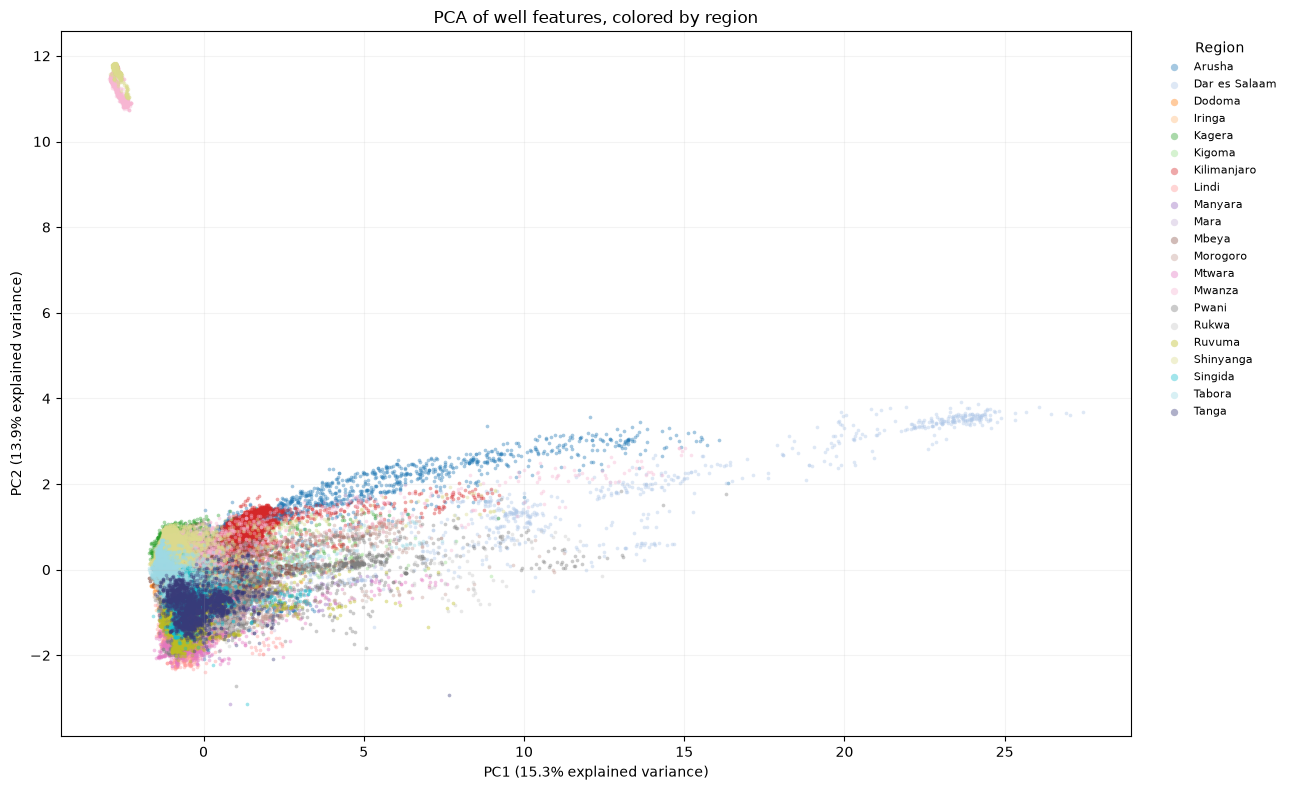

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pca_features = training_df.drop(columns=["region", "region_code", "id", "status_group"])
region_labels = training_df["region"].fillna("Unknown").astype(str)
numeric_columns = pca_features.select_dtypes(include="number").columns.tolist()
categorical_columns = pca_features.columns.difference(numeric_columns).tolist()
pca_features = pca_features.copy()
pca_features[categorical_columns] = (
    pca_features[categorical_columns].fillna("Unknown").astype(str)
)

pca_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scale", StandardScaler()),
    ]), numeric_columns),
    ("categorical", OneHotEncoder(
        min_frequency=20, max_categories=50,
        handle_unknown="infrequent_if_exist", sparse_output=False,
    ), categorical_columns),
])
pca_model = Pipeline([
    ("preprocess", pca_preprocessor),
    ("pca", PCA(n_components=2, svd_solver="randomized", random_state=42)),
])

pca_coordinates = pca_model.fit_transform(pca_features)
pca_df = pd.DataFrame(pca_coordinates, columns=["PC1", "PC2"], index=training_df.index)
pca_df["region"] = region_labels.to_numpy()
pca_df["id"] = training_df["id"].to_numpy()
explained_variance = pca_model.named_steps["pca"].explained_variance_ratio_

fig, ax = plt.subplots(figsize=(13, 8))
regions = sorted(pca_df["region"].unique())
colors = list(plt.get_cmap("tab20").colors) + list(plt.get_cmap("tab20b").colors)
for region, color in zip(regions, colors):
    points = pca_df.loc[pca_df["region"].eq(region)]
    ax.scatter(points["PC1"], points["PC2"], color=color, label=region,
               s=7, alpha=0.4, linewidths=0, rasterized=True)
ax.set(
    title="PCA of well features, colored by region",
    xlabel=f"PC1 ({explained_variance[0]:.1%} explained variance)",
    ylabel=f"PC2 ({explained_variance[1]:.1%} explained variance)",
)
ax.legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left",
          markerscale=2, frameon=False, fontsize=8)
ax.grid(alpha=0.15)
fig.tight_layout()
print(f"Two components explain {explained_variance.sum():.1%} of transformed feature variance.")
plt.show()

### 4.2. Similarity of regional feature profiles

We calculate the centroid distances between every group and average them to understand which groups are the most similar to the rest of the dataset. We find that Morogoro, nga, and Manyara are good candidates.

Most similar average region profile: Morogoro


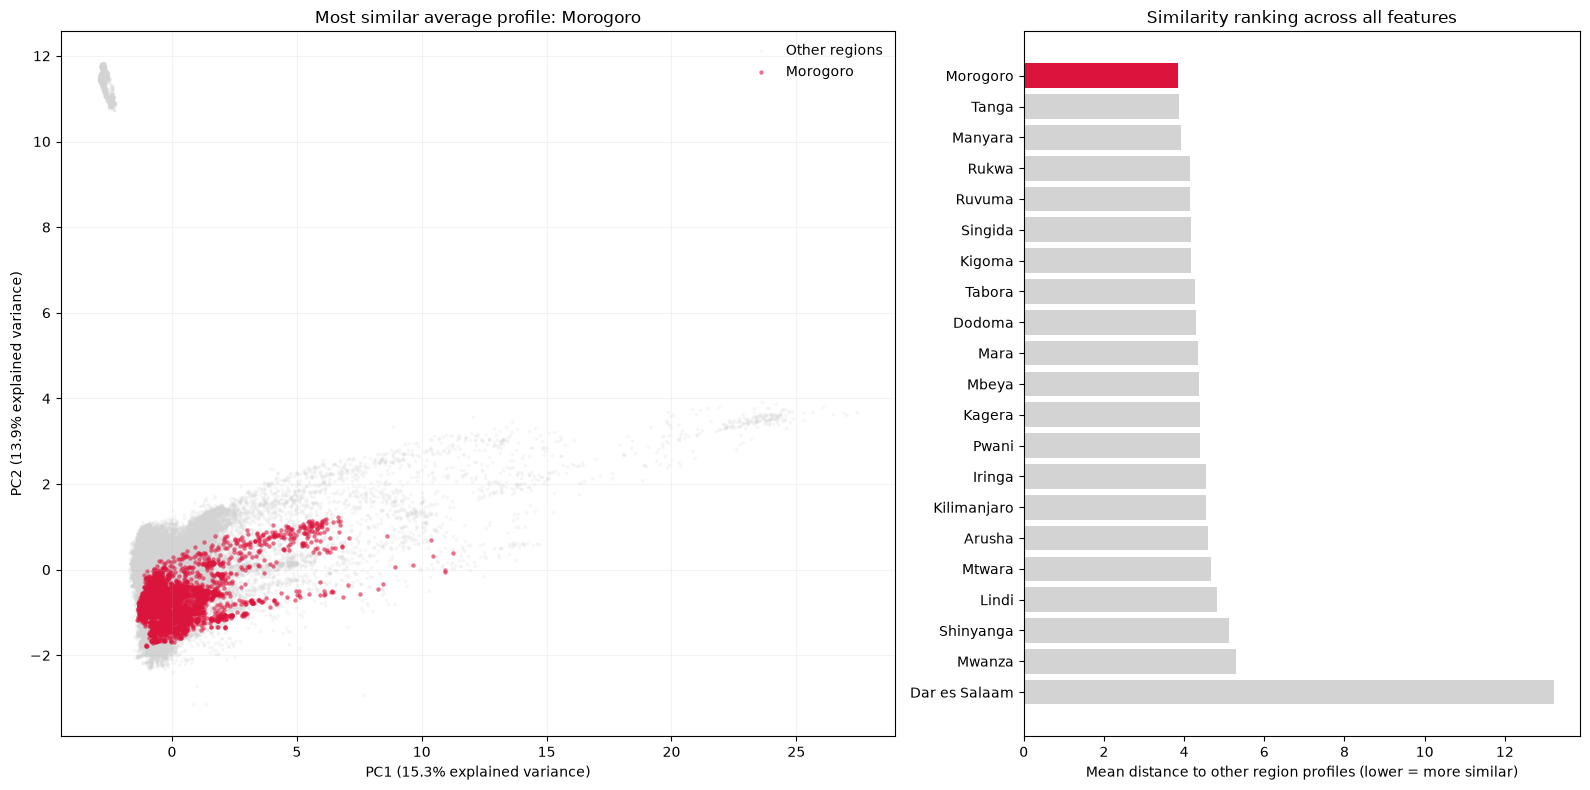

,region,mean_distance_to_other_regions
0,Morogoro,3.842123
1,Tanga,3.862614
2,Manyara,3.923487
3,Rukwa,4.147651
4,Ruvuma,4.158368
5,Singida,4.167609
6,Kigoma,4.177181
7,Tabora,4.265441
8,Dodoma,4.286710
9,Mara,4.335128


In [6]:
from sklearn.metrics import pairwise_distances

# Compare average region profiles in ALL transformed dimensions, not just PC1/PC2.
# Each region has equal weight, regardless of its number of wells.
similarity_features = pca_model.named_steps["preprocess"].transform(pca_features)
similarity_regions = sorted(pca_df["region"].unique())
region_centroids = np.vstack([
    similarity_features[pca_df["region"].eq(region).to_numpy()].mean(axis=0)
    for region in similarity_regions
])
del similarity_features
region_distance_df = pd.DataFrame(
    pairwise_distances(region_centroids, metric="euclidean"),
    index=similarity_regions, columns=similarity_regions,
)
similarity_df = pd.DataFrame({
    "region": similarity_regions,
    "mean_distance_to_other_regions": (
        region_distance_df.sum(axis=1).to_numpy() / (len(similarity_regions) - 1)
    ),
}).sort_values("mean_distance_to_other_regions").reset_index(drop=True)
most_similar_region = similarity_df.iloc[0]["region"]
highlight = pca_df["region"].eq(most_similar_region)

fig_similarity, (ax_projection, ax_ranking) = plt.subplots(
    1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1.5, 1]},
)
ax_projection.scatter(
    pca_df.loc[~highlight, "PC1"], pca_df.loc[~highlight, "PC2"],
    color="lightgray", s=6, alpha=0.2, linewidths=0, label="Other regions", rasterized=True,
)
ax_projection.scatter(
    pca_df.loc[highlight, "PC1"], pca_df.loc[highlight, "PC2"],
    color="crimson", s=10, alpha=0.6, linewidths=0,
    label=most_similar_region, rasterized=True,
)
ax_projection.set(
    title=f"Most similar average profile: {most_similar_region}",
    xlabel=f"PC1 ({explained_variance[0]:.1%} explained variance)",
    ylabel=f"PC2 ({explained_variance[1]:.1%} explained variance)",
)
ax_projection.legend(frameon=False)
ax_projection.grid(alpha=0.15)
ax_ranking.barh(
    similarity_df["region"], similarity_df["mean_distance_to_other_regions"],
    color=["crimson" if region == most_similar_region else "lightgray"
           for region in similarity_df["region"]],
)
ax_ranking.invert_yaxis()
ax_ranking.set(title="Similarity ranking across all features",
               xlabel="Mean distance to other region profiles (lower = more similar)")
fig_similarity.tight_layout()
print(f"Most similar average region profile: {most_similar_region}")
plt.show()
similarity_df

### 4.3. Geographic holdout choice

By using Morogoro in our hold-out set evaluation, we assume that its data is most represented in the rest of the dataset and that our model therefore best retains its performance.

## 5. Fit once and evaluate validation versus geographic holdout


In [7]:
X_train, X_valid, X_holdout, y_train, y_valid, y_holdout = pipeline.split(
    X_model, y, holdout_regions=holdout_regions,
)
pipeline.fit(X_train, y_train)
evaluator = ModelEvaluator()
results_df = pipeline.predict_wells(X_valid).assign(actual_status=y_valid, region=X_valid["region"])
holdout_results_df = pipeline.predict_wells(X_holdout).assign(actual_status=y_holdout, region=X_holdout["region"])
metrics_df = pd.DataFrame.from_dict({
    "validation": evaluator.metrics(y_valid, results_df["predicted_status"]),
    "geographic_holdout": evaluator.metrics(y_holdout, holdout_results_df["predicted_status"]),
}, orient="index")
display(pd.Series({"train": len(X_train), "validation": len(X_valid), "geographic_holdout": len(X_holdout)}))
display(metrics_df)
print(evaluator.classification_report(y_holdout, holdout_results_df["predicted_status"]))
display(evaluator.confusion_matrix(y_holdout, holdout_results_df["predicted_status"]))
population_importance_df = evaluator.feature_importance(pipeline)
display(population_importance_df.loc[population_importance_df["feature"].isin(
    [f"numerical__{name}" for name in population_features]
)])
probability_columns = ["id", "latitude", "longitude", "region", "probability_functional", "probability_needs_repair", "probability_non_functional"]
validation_probabilities_df = results_df[probability_columns].copy()
holdout_probabilities_df = holdout_results_df[probability_columns].copy()
holdout_probabilities_df.head()

                         precision    recall  f1-score   support

             functional       0.74      0.79      0.76      2119
functional needs repair       0.00      0.00      0.00       300
         non functional       0.69      0.76      0.72      1587

               accuracy                           0.72      4006
              macro avg       0.48      0.52      0.50      4006
           weighted avg       0.66      0.72      0.69      4006



train                 41545
validation            13849
geographic_holdout     4006
dtype: int64

,accuracy,precision,recall,f1
validation,0.794281,0.793898,0.794281,0.781688
geographic_holdout,0.717923,0.664483,0.717923,0.690133


,functional,functional needs repair,non functional
functional,1670,0,449
functional needs repair,210,0,90
non functional,381,0,1206


,feature,importance
222,numerical__population_20km,0.001286
311,numerical__population_10km,0.000944
317,numerical__population_5km,0.000926
327,numerical__Population_3km,0.000902
329,numerical__Population_1km,0.000899
343,numerical__Population_2km,0.000864


,id,latitude,longitude,region,probability_functional,probability_needs_repair,probability_non_functional
70,21990,-8.934950,35.818981,Morogoro,0.489509,0.034490,0.476001
81,65531,-7.024263,37.722953,Morogoro,0.538706,0.071578,0.389716
116,21068,-6.829501,37.487474,Morogoro,0.453337,0.031414,0.515249
141,60852,-6.771699,37.823462,Morogoro,0.681906,0.057476,0.260618
143,17687,-6.299767,37.443110,Morogoro,0.117604,0.020291,0.862105


### 5.1. Nonfunctional-class precision–recall


Average precision: 0.797
Nonfunctional wells: 1,587 / 4,006


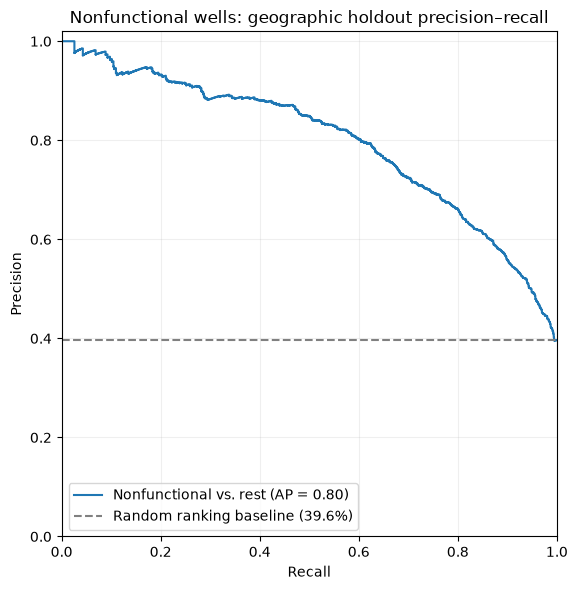

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score

# One-vs-rest: "non functional" is positive; the other two statuses are negative.
# Use ground-truth labels and continuous probabilities, not predicted classes.
nonfunctional_actual = holdout_results_df["actual_status"].eq("non functional")
nonfunctional_probability = holdout_results_df["probability_non_functional"]
nonfunctional_ap = average_precision_score(nonfunctional_actual, nonfunctional_probability)
nonfunctional_prevalence = nonfunctional_actual.mean()

fig_pr, ax_pr = plt.subplots(figsize=(8, 6))
PrecisionRecallDisplay.from_predictions(
    nonfunctional_actual, nonfunctional_probability,
    name="Nonfunctional vs. rest", ax=ax_pr,
)
ax_pr.axhline(
    nonfunctional_prevalence, color="gray", linestyle="--",
    label=f"Random ranking baseline ({nonfunctional_prevalence:.1%})",
)
ax_pr.set(title="Nonfunctional wells: geographic holdout precision–recall",
          xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
ax_pr.grid(alpha=0.2)
ax_pr.legend(loc="lower left")
fig_pr.tight_layout()
print(f"Average precision: {nonfunctional_ap:.3f}")
print(f"Nonfunctional wells: {nonfunctional_actual.sum():,} / {len(nonfunctional_actual):,}")
plt.show()

## 6. Define the water-access experiment

To align ourselves with the goals of this project, we further evaluate based on additional water access. In line with [UNICEF's guidelines](https://data.unicef.org/topic/water-and-sanitation/drinking-water/), we define water access as a 30-minute round trip to a functional water well. We assume that a water well is functional either by ground-truth, or by correct non-functional prediction of our model. To account for low vehicle ownership in Tanzania, we assume a 30-minute roundtrip can be defined as a 2.5KM walkable distance.

### 6.1. Annotate regional and nearby population scopes

We use administrative boundaries to identify population pixels within Morogoro and evaluate two scopes: Full regional population and the population limit within 2.5KM of any candidate well. Overlapping catchments count each population pixel only once. 

In [9]:
boundaries = gpd.read_file(boundaries_path)
population_with_regions_df = assign_population_regions(population_df, boundaries, population_crs)

### 6.2. Confidence-first selection against equal-budget random checks

To accomodate for a use-scenario with a limited budget (ie 100 repairs), we guide our labeling through our model's predicted confidence on the non-functional class.

Evaluating on increased water access, we see that the random baseline actually performs better than our model.

In [10]:
selected_wells_df = select_interventions(holdout_results_df, budget_n=budget_n)
random_selected_wells_df = select_interventions(
    holdout_results_df, budget_n=len(selected_wells_df), strategy="random", random_state=random_state,
)
access_df = build_population_access_df(
    population_with_regions_df, holdout_results_df, population_crs=population_crs,
    nearby_radius_m=nearby_radius_m, selected_well_ids=selected_wells_df["id"],
    random_selected_well_ids=random_selected_wells_df["id"], region_names=holdout_regions,
)
filtered_population_df = access_df.loc[access_df["within_candidate_radius"]].copy()
region_population_access_df = access_df.loc[access_df["within_region"]].copy()
access_kpis = calculate_access_kpis(access_df, access_distance_m=access_distance_m)
display(pd.DataFrame(access_kpis))
display(region_population_access_df.head())

,nearby_population,full_region
population_total,2.666507e+06,3.741706e+06
population_with_access_before,2.378565e+06,2.366147e+06
population_without_access_before,2.879428e+05,1.375559e+06
population_with_access_after,2.424080e+06,2.404488e+06
population_without_access_after,2.424272e+05,1.337218e+06
population_gaining_access,4.551568e+04,3.834102e+04
coverage_before_pct,8.920150e+01,6.323712e+01
coverage_after_pct,9.090844e+01,6.426182e+01
coverage_improvement_pp,1.706940e+00,1.024694e+00
population_with_access_random,2.425281e+06,2.410267e+06


,pixel_id,x,y,population,region,within_tanzania,distance_to_nearest_candidate_well_m,within_candidate_radius,within_region,nearest_functional_well_id,distance_to_nearest_functional_well_m,nearest_functional_well_without_intervention_id,distance_to_nearest_functional_well_without_intervention_m,nearest_functional_well_with_random_interventions_id,distance_to_nearest_functional_well_with_random_interventions_m
313835,774114,37.462499,-5.820833,8.664004,Morogoro,True,2562.073326,False,True,13668,2562.073326,54433,7365.958518,54433,7365.958518
313836,774115,37.470832,-5.820833,20.581339,Morogoro,True,1827.772654,True,True,13668,1827.772654,54433,7150.787828,54433,7150.787828
313837,774116,37.479166,-5.820833,4.206622,Morogoro,True,1347.906926,True,True,13668,1347.906926,54433,7050.503412,54433,7050.503412
313838,774117,37.487499,-5.820833,2.526273,Morogoro,True,1411.566629,True,True,13668,1411.566629,54433,7069.995776,54433,7069.995776
313839,774118,37.495832,-5.820833,185.074219,Morogoro,True,953.725627,True,True,1698,953.725627,54433,7208.293301,54433,7208.293301


### 6.3. Population-weighted access calculation

We hypothesize that our failure to beat the random baseline is due to high-confidence wells being possibly near low-population areas. Therefore we adjust our selection process and weigh the confidence with the nearby population.

In [11]:
distance_columns = {
    "no_repairs": "distance_to_nearest_functional_well_without_intervention_m",
    "confidence_first": "distance_to_nearest_functional_well_m",
    "random": "distance_to_nearest_functional_well_with_random_interventions_m",
}
population_without_access = pd.Series({
    scenario: filtered_population_df.loc[filtered_population_df[column].gt(access_distance_m), "population"].sum()
    for scenario, column in distance_columns.items()
}, name="population_without_access")
population_without_access

no_repairs          287942.835318
confidence_first    242427.150857
random              241226.429840
Name: population_without_access, dtype: float64

In [12]:
objective_population_df = population_with_regions_df.loc[population_with_regions_df["region"].isin(holdout_regions)].copy()
candidates_df = holdout_results_df[["id", "latitude", "longitude", "probability_non_functional"]].copy()
known_functional_wells_df = holdout_results_df.loc[
    holdout_results_df["actual_status"].eq("functional"), ["id", "latitude", "longitude"],
].copy()
access_selected_wells_df = select_access_interventions(
    objective_population_df, candidates_df, known_functional_wells_df,
    budget_n=len(selected_wells_df), population_crs=population_crs, access_distance_m=access_distance_m,
)
access_optimized_df = build_population_access_df(
    population_with_regions_df, holdout_results_df, population_crs=population_crs,
    nearby_radius_m=nearby_radius_m, selected_well_ids=access_selected_wells_df["id"],
    random_selected_well_ids=random_selected_wells_df["id"], region_names=holdout_regions,
)
access_optimized_kpis = calculate_access_kpis(access_optimized_df, access_distance_m=access_distance_m)
display(access_selected_wells_df.head(10))

,id,latitude,longitude,probability_non_functional,selection_rank,expected_population_gain,cumulative_expected_population_gain
33768,1833,-6.139163,36.868125,0.721029,1,21335.005796,21335.005796
51817,42303,-6.725480,37.648831,0.930502,2,14129.060908,35464.066704
36683,45575,-7.259100,37.742714,0.993315,3,4262.529841,39726.596546
1273,48536,-6.140398,36.982042,0.534623,4,3968.290895,43694.887441
51856,68163,-6.765039,37.661444,0.270466,5,3816.793290,47511.680731
17919,39684,-7.050389,37.504986,0.978169,6,3418.605846,50930.286577
25472,1835,-6.120502,37.576634,0.654414,7,3233.304011,54163.590588
53101,25179,-8.838446,35.775865,0.958536,8,3074.626397,57238.216986
30782,6214,-7.033821,36.908558,0.878814,9,2926.817322,60165.034308
4089,68640,-6.772106,38.214608,0.995682,10,2653.888631,62818.922939


### 7.1. Compare confidence, random, and expected-access strategies

Using our weighted selection process, we outperform the randomized baseline on the nearby ppulation by a rough factor of 5. On the full region scenario, we see similar results.

In [13]:
comparison_rows = []
for scope, optimized in access_optimized_kpis.items():
    previous = access_kpis[scope]
    for strategy, gain, coverage, improvement in [
        ("confidence_first", previous["population_gaining_access"],
         previous["coverage_after_pct"], previous["coverage_improvement_pp"]),
        ("random_seed_42", previous["population_gaining_access_random"],
         previous["coverage_random_pct"], previous["coverage_improvement_random_pp"]),
        ("expected_population_access", optimized["population_gaining_access"],
         optimized["coverage_after_pct"], optimized["coverage_improvement_pp"]),
    ]:
        comparison_rows.append({
            "scope": scope, "strategy": strategy,
            "pump_checks": len(access_selected_wells_df),
            "population_gaining_access": gain,
            "coverage_before_pct": previous["coverage_before_pct"],
            "coverage_after_pct": coverage,
            "coverage_improvement_pp": improvement,
        })
strategy_comparison_df = pd.DataFrame(comparison_rows).set_index(["scope", "strategy"])
strategy_comparison_df

pump_checks  ...  coverage_improvement_pp
scope             strategy                                 ...                         
nearby_population confidence_first                    300  ...                 1.706940
                  random_seed_42                      300  ...                 1.751970
                  expected_population_access          300  ...                 9.501455
full_region       confidence_first                    300  ...                 1.024694
                  random_seed_42                      300  ...                 1.179147
                  expected_population_access          300  ...                 6.470053

[6 rows x 5 columns]

### 7.2. Distance distributions before and after priority repairs


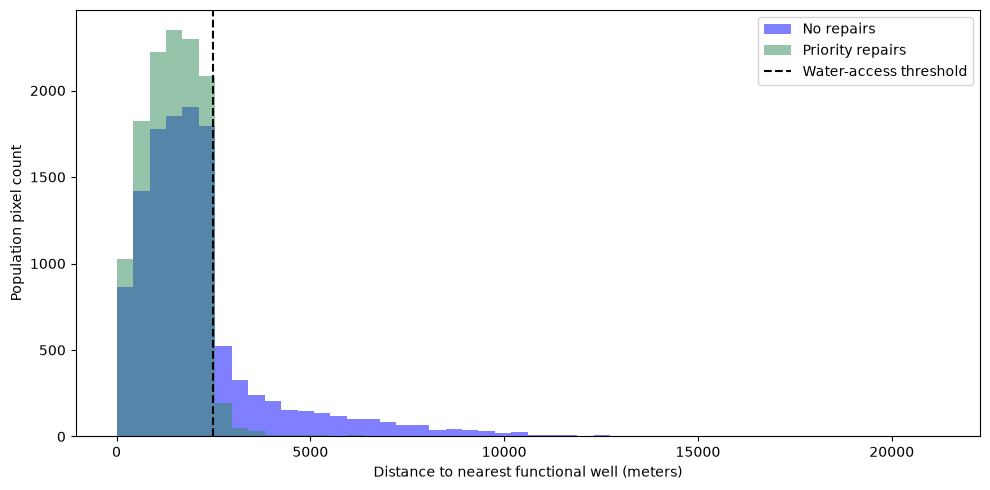

In [14]:
nearby_optimized_df = access_optimized_df.loc[access_optimized_df["within_candidate_radius"]].copy()
columns = ["distance_to_nearest_functional_well_m", "distance_to_nearest_functional_well_without_intervention_m"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist([nearby_optimized_df[column].replace([np.inf, -np.inf], np.nan).dropna() for column in columns],
        bins=50, histtype="stepfilled", color=["seagreen", "blue"], alpha=0.5,
        label=["Priority repairs", "No repairs"])
ax.axvline(access_distance_m, color="black", linestyle="--", label="Water-access threshold")
ax.set(xlabel="Distance to nearest functional well (meters)", ylabel="Population pixel count")
ax.legend()
fig.tight_layout()
plt.show()

## 8. Outputs for regional maps and repair planning


In [15]:
region_population_access_df = access_optimized_df.loc[access_optimized_df["within_region"]].copy()
filtered_population_df = nearby_optimized_df
repair_plan_df = access_selected_wells_df.merge(
    X_raw[["id", "wpt_name", "region", "lga", "ward", "subvillage"]],
    on="id", how="left", validate="one_to_one",
)
display(repair_plan_df.head())
display(region_population_access_df.head())

,id,latitude,longitude,probability_non_functional,selection_rank,expected_population_gain,cumulative_expected_population_gain,wpt_name,region,lga,ward,subvillage
0,1833,-6.139163,36.868125,0.721029,1,21335.005796,21335.005796,No.7,Morogoro,Kilosa,Lumbiji,Ungu Rd
1,42303,-6.725480,37.648831,0.930502,2,14129.060908,35464.066704,Chazo Cha Kilongo,Morogoro,Morogoro Urban,Kihonda,Kiloka
2,45575,-7.259100,37.742714,0.993315,3,4262.529841,39726.596546,Kwa Mzee Bonde,Morogoro,Morogoro Rural,Kolero,Lukami
3,48536,-6.140398,36.982042,0.534623,4,3968.290895,43694.887441,Kwa Gumbo,Morogoro,Kilosa,Mamboya,Mgongwe
4,68163,-6.765039,37.661444,0.270466,5,3816.793290,47511.680731,Kwa Rwegoshora,Morogoro,Morogoro Urban,Kihonda,Magereza


,pixel_id,x,y,population,region,within_tanzania,distance_to_nearest_candidate_well_m,within_candidate_radius,within_region,nearest_functional_well_id,distance_to_nearest_functional_well_m,nearest_functional_well_without_intervention_id,distance_to_nearest_functional_well_without_intervention_m,nearest_functional_well_with_random_interventions_id,distance_to_nearest_functional_well_with_random_interventions_m
313835,774114,37.462499,-5.820833,8.664004,Morogoro,True,2562.073326,False,True,13668,2562.073326,54433,7365.958518,54433,7365.958518
313836,774115,37.470832,-5.820833,20.581339,Morogoro,True,1827.772654,True,True,13668,1827.772654,54433,7150.787828,54433,7150.787828
313837,774116,37.479166,-5.820833,4.206622,Morogoro,True,1347.906926,True,True,13668,1347.906926,54433,7050.503412,54433,7050.503412
313838,774117,37.487499,-5.820833,2.526273,Morogoro,True,1411.566629,True,True,13668,1411.566629,54433,7069.995776,54433,7069.995776
313839,774118,37.495832,-5.820833,185.074219,Morogoro,True,953.725627,True,True,1698,953.725627,54433,7208.293301,54433,7208.293301
